In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from typing import Tuple

df = pd.read_parquet("../data/cisto.parquet")

# 3.1. Najprodavaniji proizvodi

In [2]:
by_product = (df.groupby(["StockCode", "Description"])
                  .agg(Kolicina=("Quantity", "sum"),
                       Prihod=("TotalPrice", "sum"),
                       Kupaca=("CustomerID", "nunique"))
                  .reset_index())

## Po prihodu

In [3]:
print(by_product.nlargest(10, "Prihod")[["Description", "Prihod", "Kupaca"]])

                             Description     Prihod  Kupaca
1846            REGENCY CAKESTAND 3 TIER  277656.25    1314
4723  WHITE HANGING HEART T-LIGHT HOLDER  247048.01    1490
3263         PAPER CRAFT , LITTLE BIRDIE  168469.60       1
4698             JUMBO BAG RED RETROSPOT  134307.44     860
4429       ASSORTED COLOUR BIRD ORNAMENT  124351.86    1010
3606                       PARTY BUNTING  103283.38     894
2761      MEDIUM CERAMIC TOP STORAGE JAR   81416.73     138
1437      PAPER CHAIN KIT 50'S CHRISTMAS   76598.18     896
3908                       CHILLI LIGHTS   69084.30     304
4702                JUMBO BAG STRAWBERRY   64127.77     549


## Po količini

In [4]:
print(by_product.nlargest(10, "Kolicina")[["Description", "Kolicina", "Kupaca"]])

                             Description  Kolicina  Kupaca
4006   WORLD WAR 2 GLIDERS ASSTD DESIGNS    105185     482
4723  WHITE HANGING HEART T-LIGHT HOLDER     91757    1490
3263         PAPER CRAFT , LITTLE BIRDIE     80995       1
4429       ASSORTED COLOUR BIRD ORNAMENT     78234    1010
2761      MEDIUM CERAMIC TOP STORAGE JAR     77916     138
4698             JUMBO BAG RED RETROSPOT     74224     860
114                   BROCADE RING PURSE     70082     215
1347  PACK OF 60 PINK PAISLEY CAKE CASES     54592     767
4568         60 TEATIME FAIRY CAKE CASES     52828     822
655     PACK OF 72 RETRO SPOT CAKE CASES     45129     632


# 3.2 Pareto analiza

1,146 proizvoda (21.7% asortimana) = 80% prihoda


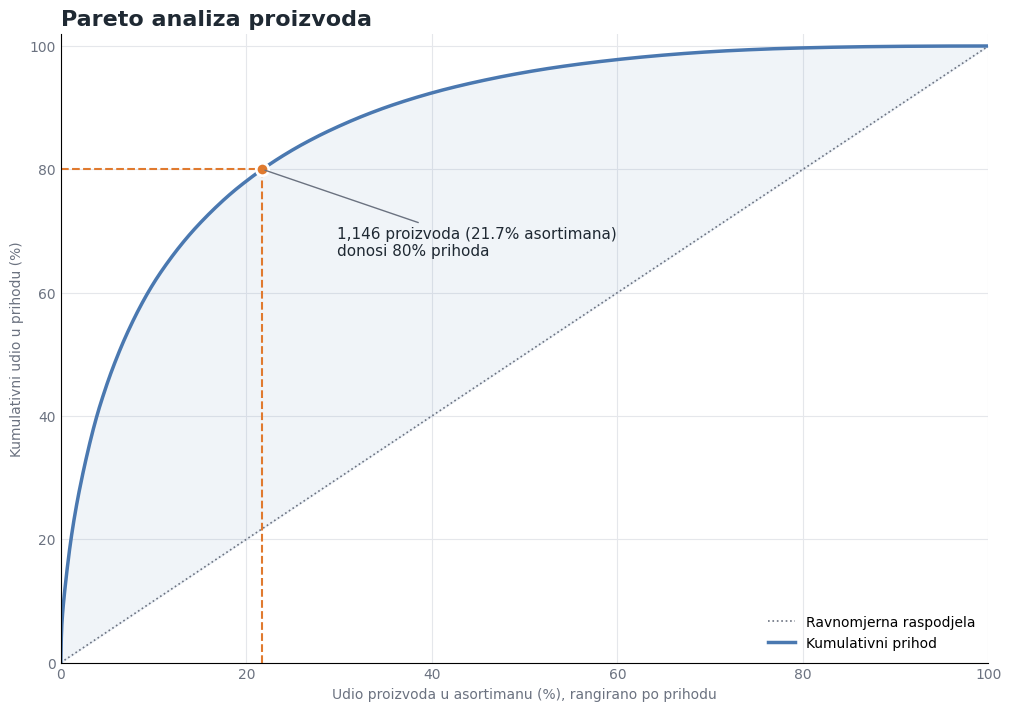

In [5]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE, ACCENT = "#4a78b0", "#e07a2f"

s = by_product.sort_values("Prihod", ascending=False).reset_index(drop=True)
s["Kumulativno %"] = s["Prihod"].cumsum() / s["Prihod"].sum() * 100
s["Udeo proizvoda %"] = (s.index + 1) / len(s) * 100

until80 = int((s["Kumulativno %"] < 80).sum()) + 1
stake80 = until80 / len(s) * 100
print(f"{until80:,} proizvoda ({stake80:.1f}% asortimana) = 80% prihoda")

fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

x = np.concatenate([[0], s["Udeo proizvoda %"]])
y = np.concatenate([[0], s["Kumulativno %"]])

ax.plot([0, 100], [0, 100], color=MUTED, linestyle=":", linewidth=1.2,
        label="Ravnomjerna raspodjela")
ax.plot(x, y, color=BASE, linewidth=2.5, label="Kumulativni prihod")
ax.fill_between(x, y, x, color=BASE, alpha=0.08)

ax.hlines(80, 0, stake80, color=ACCENT, linestyle="--", linewidth=1.5)
ax.vlines(stake80, 0, 80, color=ACCENT, linestyle="--", linewidth=1.5)
ax.plot(stake80, 80, "o", color=ACCENT, markersize=9,
        markeredgecolor="white", markeredgewidth=2)
ax.annotate(f"{until80:,} proizvoda ({stake80:.1f}% asortimana)\ndonosi 80% prihoda",
            xy=(stake80, 80), xytext=(stake80 + 8, 66), fontsize=11, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED))

ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.set_title("Pareto analiza proizvoda", loc="left", fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Udio proizvoda u asortimanu (%), rangirano po prihodu", color=MUTED)
ax.set_ylabel("Kumulativni udio u prihodu (%)", color=MUTED)

ax.tick_params(colors=MUTED, length=0)
ax.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

ax.legend(frameon=False, loc="lower right")
plt.show()

# 3.1 RFM Analiza

In [7]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print(f"Referentni datum: {reference_date}")

Referentni datum: 2011-12-10 12:50:00


In [8]:
rfm = (df.groupby("CustomerID")
         .agg(Recency=("InvoiceDate", lambda s: (reference_date - s.max()).days),
              Frequency=("InvoiceNo", "nunique"), 
              Monetary=("TotalPrice", "sum"))    
         .reset_index())

rfm["Monetary"] = rfm["Monetary"].round(2)
print(f"Ukupno kupaca u RFM tabeli: {len(rfm):,}")
print(rfm.head(10))

Ukupno kupaca u RFM tabeli: 5,852
   CustomerID  Recency  Frequency  Monetary
0       12346      326          3  77352.96
1       12347        2          8   4921.53
2       12348       75          5   1658.40
3       12349       19          3   3678.69
4       12350      310          1    294.40
5       12351      375          1    300.93
6       12352       36          9   1729.54
7       12353      204          2    406.76
8       12354      232          1   1079.40
9       12355      214          2    947.61


In [9]:
print(f"Recency   — medijana: {rfm['Recency'].median():.0f} | mean: {rfm['Recency'].mean():.1f} | max: {rfm['Recency'].max():.1f}")
print(f"Frequency   — medijana: {rfm['Frequency'].median():.0f} | mean: {rfm['Frequency'].mean():.1f} | max: {rfm['Frequency'].max():.1f}")
print(f"Monetary   — medijana: {rfm['Monetary'].median():.0f} | mean: {rfm['Monetary'].mean():.1f} | max: {rfm['Monetary'].max():.1f}")

Recency   — medijana: 95 | mean: 200.2 | max: 739.0
Frequency   — medijana: 3 | mean: 6.3 | max: 373.0
Monetary   — medijana: 856 | mean: 2916.7 | max: 580987.0


# 3.4 Skorovanje (1–5) i segmenti kupaca

In [10]:
def quintiles(series: pd.Series, ascending: bool) -> pd.qcut:
    rang = series.rank(method="first", ascending=ascending)
    return pd.qcut(rang, 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["R"] = quintiles(rfm["Recency"],   ascending=False)
rfm["F"] = quintiles(rfm["Frequency"], ascending=True)
rfm["M"] = quintiles(rfm["Monetary"],  ascending=True)

print(rfm[["CustomerID", "Recency", "Frequency", "Monetary", "R", "F", "M"]].head(10))

   CustomerID  Recency  Frequency  Monetary  R  F  M
0       12346      326          3  77352.96  2  3  5
1       12347        2          8   4921.53  5  4  5
2       12348       75          5   1658.40  3  4  4
3       12349       19          3   3678.69  4  3  5
4       12350      310          1    294.40  2  1  2
5       12351      375          1    300.93  2  1  2
6       12352       36          9   1729.54  4  5  4
7       12353      204          2    406.76  2  2  2
8       12354      232          1   1079.40  2  1  3
9       12355      214          2    947.61  2  2  3


## Dodeljivanje segmenata na osnovu R i F skora (25 kombinacija)

In [12]:
segment_map = {
    r"[1-2][1-2]": "Izgubljeni",
    r"[1-2][3-4]": "U riziku",
    r"[1-2]5":     "Ne smijemo ih izgubiti",
    r"3[1-2]":     "Uspavani",
    r"33":         "Treba im pažnja",
    r"[3-4][4-5]": "Lojalni",
    r"41":         "Obećavajući",
    r"51":         "Novi kupci",
    r"[4-5][2-3]": "Potencijalno lojalni",
    r"5[4-5]":     "Šampioni",
}

rf = rfm["R"].astype(str) + rfm["F"].astype(str)
rfm["Segment"] = rf.replace(segment_map, regex=True)

summary = (rfm.groupby("Segment")
              .agg(Kupaca=("CustomerID", "count"), Prihod=("Monetary", "sum")))
summary["Udeo kupaca %"] = summary["Kupaca"] / summary["Kupaca"].sum() * 100
summary["Udeo prihoda %"] = summary["Prihod"] / summary["Prihod"].sum() * 100

print(summary.round(1).sort_values("Udeo prihoda %", ascending=False))

                        Kupaca     Prihod  Udeo kupaca %  Udeo prihoda %
Segment                                                                 
Šampioni                   830  8781126.4           14.2            51.4
Lojalni                   1151  4658851.8           19.7            27.3
U riziku                   759  1094280.6           13.0             6.4
Potencijalno lojalni       710   811734.6           12.1             4.8
Izgubljeni                1510   620443.0           25.8             3.6
Ne smijemo ih izgubiti      72   503405.1            1.2             2.9
Treba im pažnja            268   338417.5            4.6             2.0
Uspavani                   385   205868.2            6.6             1.2
Obećavajući                116    36670.6            2.0             0.2
Novi kupci                  51    17784.8            0.9             0.1


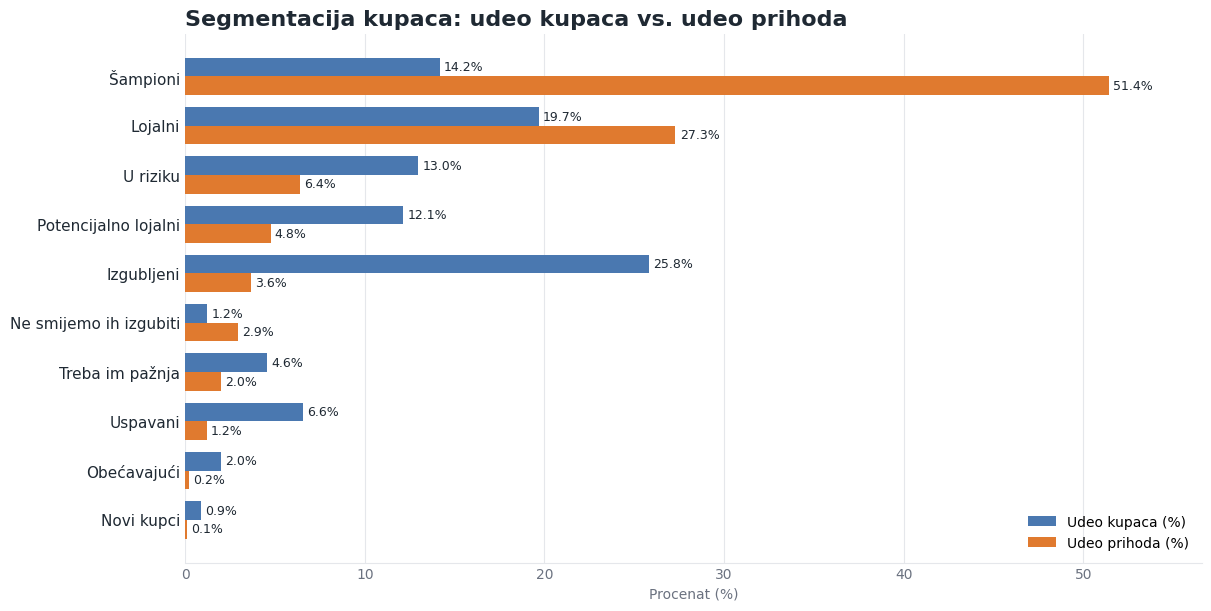

In [13]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE, ACCENT = "#4a78b0", "#e07a2f"

summary_graph = summary.sort_values("Udeo prihoda %", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
y = np.arange(len(summary_graph))
height = 0.38

b1 = ax.barh(y + height / 2, summary_graph["Udeo kupaca %"], height=height,
             label="Udeo kupaca (%)", color=BASE)
b2 = ax.barh(y - height / 2, summary_graph["Udeo prihoda %"], height=height,
             label="Udeo prihoda (%)", color=ACCENT)

ax.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=9, color=INK)
ax.bar_label(b2, fmt="%.1f%%", padding=3, fontsize=9, color=INK)

ax.set_yticks(y)
ax.set_yticklabels(summary_graph.index, fontsize=11, color=INK)
ax.set_xlabel("Procenat (%)", color=MUTED)
ax.set_title("Segmentacija kupaca: udeo kupaca vs. udeo prihoda",
             loc="left", fontsize=16, fontweight="bold", color=INK)
ax.margins(x=0.1)

ax.tick_params(axis="x", colors=MUTED, length=0)
ax.tick_params(axis="y", length=0)
ax.set_axisbelow(True)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

ax.legend(frameon=False, loc="lower right")
plt.show()

In [14]:
rfm.to_parquet("../data/rfm.parquet", index=False)